# 01 · Data and company selection

**Question this notebook answers:** what data are we reserving, is it fit for purpose, and which company should the review focus on?

### Why this dataset

My first reserving project used `genins`, a textbook triangle bundled with the `chainladder` package. It has no premium (so no independent BF prior), no incurred data (so no paid vs incurred comparison) and no known outcome (so no way to test whether a method was right).

The **CAS Loss Reserving Database** (Meyers & Shi, 2011) fixes all three. It holds real data from **NAIC Schedule P, Part 1**: the annual statutory filing in which every US property & casualty insurer reports, by line of business and accident year:

| Field | Used for |
|---|---|
| Cumulative paid losses (+ defence & cost containment) | paid triangle |
| Incurred losses, i.e. case reserves **plus bulk/IBNR** | the company's own estimate |
| Bulk + IBNR reserves | removed to get **case incurred** (claims-handler information only) |
| Net earned premium | exposure base for the BF / Cape Cod prior |
| Posted reserve at 31/12/1997 | what the company actually booked |

The key feature: each accident year 1988-1997 is followed for **ten** development years, so the file contains the **full square**. We reserve as at **31/12/1997** using only the upper triangle, then use the lower triangle as *hindsight* to judge the methods (notebook 06).

Amounts are **USD thousands, net of reinsurance**. Line of business: **commercial auto liability**, a short-to-medium-tailed casualty line (bodily injury and property damage from business vehicles).

### Second data source

Schedule P is aggregate data. It has no claim counts or individual claims, so large-loss and inflation work needs claim-level data. Notebook 07 uses **SPLICE** synthetic individual claims for that.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

## 1. Load and check the raw file

In [2]:
df = D.load_cas()
print(f"{len(df):,} rows | {df['grcode'].nunique()} companies | accident years {df['ay'].min()}-{df['ay'].max()} | development ages {df['dev'].min()}-{df['dev'].max()}")
df[df["grcode"] == cfg.STUDY_GRCODE].head(12)

15,800 rows | 158 companies | accident years 1988-1997 | development ages 1-10


,grcode,company,ay,cal,dev,reported,paid,bulk,premium_direct,premium_ceded,premium,single_entity,posted_reserve_97,case_incurred,observed
2300,2712,Pennsylvania Natl Ins Grp,1988,1988,1,25729,5407,10531,47083,4209,42874,0,75716,15198,True
2301,2712,Pennsylvania Natl Ins Grp,1988,1989,2,30149,14422,6311,47083,4209,42874,0,75716,23838,True
2302,2712,Pennsylvania Natl Ins Grp,1988,1990,3,27122,19063,1358,47083,4209,42874,0,75716,25764,True
2303,2712,Pennsylvania Natl Ins Grp,1988,1991,4,26836,22447,527,47083,4209,42874,0,75716,26309,True
2304,2712,Pennsylvania Natl Ins Grp,1988,1992,5,26754,24142,309,47083,4209,42874,0,75716,26445,True
2305,2712,Pennsylvania Natl Ins Grp,1988,1993,6,27620,25404,167,47083,4209,42874,0,75716,27453,True
2306,2712,Pennsylvania Natl Ins Grp,1988,1994,7,27405,26829,78,47083,4209,42874,0,75716,27327,True
2307,2712,Pennsylvania Natl Ins Grp,1988,1995,8,27569,27202,61,47083,4209,42874,0,75716,27508,True
2308,2712,Pennsylvania Natl Ins Grp,1988,1996,9,27596,27443,36,47083,4209,42874,0,75716,27560,True
2309,2712,Pennsylvania Natl Ins Grp,1988,1997,10,27590,27449,22,47083,4209,42874,0,75716,27568,True


Basic integrity checks. A full square needs exactly 100 rows per company (10 accident years × 10 ages), and premium should not change with development age.

In [3]:
rows_per_company = df.groupby("grcode").size()
prem_constant = df.groupby(["grcode", "ay"])["premium"].nunique().eq(1).all()
checks = pd.Series({
    "companies with a full 10x10 square": int((rows_per_company == 100).sum()),
    "companies with missing rows": int((rows_per_company != 100).sum()),
    "missing values": int(df.isna().sum().sum()),
    "premium constant within each AY": bool(prem_constant),
    "cells with paid > reported incurred (by >1%)": int((df["paid"] > df["reported"] * 1.01).sum()),
    "companies with zero premium in some AY": int(df.groupby(["grcode", "ay"])["premium"].first().eq(0).groupby("grcode").any().sum()),
})
checks.to_frame("value")

,value
companies with a full 10x10 square,158
companies with missing rows,0
missing values,0
premium constant within each AY,True
cells with paid > reported incurred (by >1%),131
companies with zero premium in some AY,63


The file is structurally complete, but many entries are tiny or dormant books: zero premium in some years, zero losses, or erratic movements. Those can't support a triangle-based analysis, which is why the next step screens companies.

## 2. Screen companies: using only information available at 31/12/1997

The study company must be chosen **without looking at how its reserves turned out**, otherwise the back-test is contaminated. `screen_companies` therefore uses the upper triangle only. The criteria and the reasoning behind each:

| Criterion | Threshold | Why |
|---|---|---|
| Minimum annual net premium | ≥ $20m every year | enough volume for stable link ratios |
| Premium stability (CV across AYs) | ≤ 30% | big swings in volume usually mean mix changes, which break CL |
| Zero or negative cumulative cells | none | a triangle with zeros can't be developed |
| Negative paid increments | ≤ 5 | a few are normal (salvage & subrogation); many suggest data problems |

In [4]:
screen = D.screen_companies(df)
eligible = screen[screen["eligible"]]
cols = ["grcode", "company", "premium_mean", "premium_cv", "ceded_share", "negative_paid_increments",
        "negative_case_increments", "bulk_share_latest", "reported_lr_latest"]
print(f"{len(eligible)} of {len(screen)} companies pass the screen")
eligible[cols].style.format({"premium_mean": "{:,.0f}", "premium_cv": "{:.1%}", "ceded_share": "{:.1%}",
                             "bulk_share_latest": "{:.1%}", "reported_lr_latest": "{:.1%}"}).hide(axis="index")

9 of 158 companies pass the screen


grcode,company,premium_mean,premium_cv,ceded_share,negative_paid_increments,negative_case_increments,bulk_share_latest,reported_lr_latest
1767,State Farm Mut Grp,"354,380",12.0%,1.7%,0,0,7.4%,62.2%
388,Federal Ins Co Grp,"108,615",18.3%,14.8%,0,9,8.2%,66.6%
2623,Canal Ins Co Grp,"79,778",22.4%,36.1%,3,37,0.9%,64.2%
2135,Erie Ins Exchange Grp,"66,733",29.7%,0.1%,0,11,10.4%,75.9%
620,Employers Mut Co Of Des Moines,"55,312",29.8%,2.4%,0,23,4.2%,69.0%
7080,New Jersey Manufacturers Grp,"52,671",9.8%,1.1%,0,7,9.1%,63.3%
2712,Pennsylvania Natl Ins Grp,"46,282",12.8%,10.8%,0,5,10.3%,75.2%
26077,Lancer Ins Co,"28,752",14.2%,35.3%,0,5,6.3%,72.2%
4839,FL Farm Bureau Grp,"24,620",8.9%,7.8%,1,20,2.5%,63.6%


### Choosing between the eligible companies

All nine are usable. I chose **Pennsylvania National Insurance Group (GRCODE 2712)**:

* **Representative size and profile.** About $46m of net premium a year from a regional commercial lines writer. That's closer to a typical mid-market GI book than State Farm (a personal-lines giant, ~25% of the industry total, which would also dominate the industry benchmark) or Federal/Chubb (large specialty).
* **Stable volume** (premium CV 13%) and **clean data**: no negative paid increments, few negative case movements.
* **Meaningful IBNR**: bulk reserves are ~10% of reported incurred, among the highest of the eligible group. The company relies materially on IBNR, so the choice of method matters.
* **Low reinsurance** (11% of premium ceded), so net data reflects the underlying claims process rather than reinsurance structure.

The other eligible companies aren't wasted. Notebook 06 back-tests every method on **31 companies**, so conclusions about which method works don't rest on one company.

## 3. The study company at a glance

In [5]:
co = D.company(df, cfg.STUDY_GRCODE)
universe = D.backtest_universe(df)
ind = D.industry(df, exclude=cfg.STUDY_GRCODE, grcodes=universe)

up = df[(df["grcode"] == cfg.STUDY_GRCODE) & df["observed"]]
latest = up.sort_values("dev").groupby("ay").last()
summary = pd.DataFrame({
    "net_premium": co.premium,
    "paid_to_date": co.paid.latest_diagonal(),
    "case_incurred": co.case.latest_diagonal(),
    "bulk_ibnr_held": latest["bulk"],
    "reported_incurred": latest["reported"],
})
summary["reported_LR"] = summary["reported_incurred"] / summary["net_premium"]
summary["paid_to_case"] = summary["paid_to_date"] / summary["case_incurred"]
summary.loc["Total"] = summary.sum(numeric_only=True)
summary.loc["Total", ["reported_LR", "paid_to_case"]] = [summary.loc["Total", "reported_incurred"] / summary.loc["Total", "net_premium"],
                                                         summary.loc["Total", "paid_to_date"] / summary.loc["Total", "case_incurred"]]
summary.style.format({c: "{:,.0f}" for c in summary.columns[:5]} | {"reported_LR": "{:.1%}", "paid_to_case": "{:.1%}"})

,net_premium,paid_to_date,case_incurred,bulk_ibnr_held,reported_incurred,reported_LR,paid_to_case
1988,"42,874","27,449","27,568",22,"27,590",64.4%,99.6%
1989,"38,829","29,444","29,619",37,"29,656",76.4%,99.4%
1990,"43,001","30,656","30,743",50,"30,793",71.6%,99.7%
1991,"41,840","23,465","24,176",96,"24,272",58.0%,97.1%
1992,"44,525","27,168","27,612",221,"27,833",62.5%,98.4%
1993,"50,923","33,803","35,987",724,"36,711",72.1%,93.9%
1994,"56,601","39,702","44,210","3,221","47,431",83.8%,89.8%
1995,"54,609","32,406","40,550","6,152","46,702",85.5%,79.9%
1996,"47,204","21,831","32,432","6,590","39,022",82.7%,67.3%
1997,"42,412","9,076","19,392","18,634","38,026",89.7%,46.8%


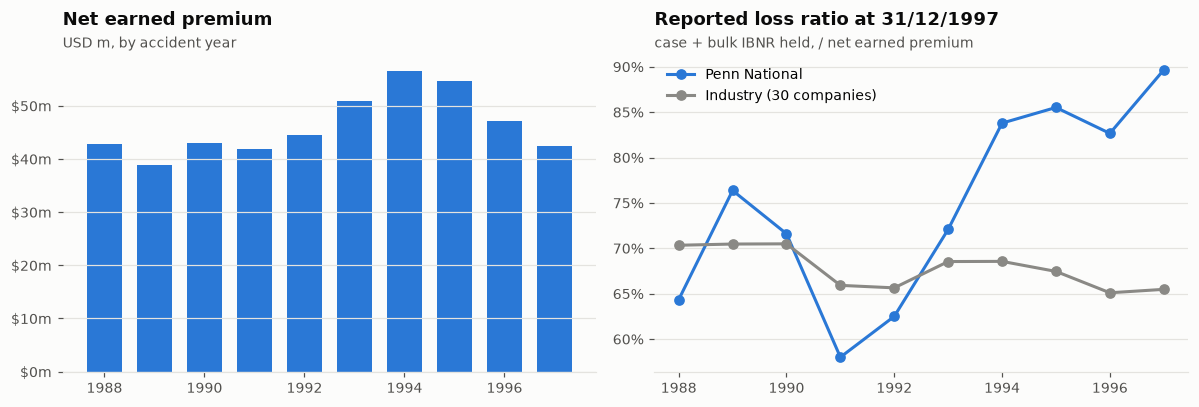

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.bar(co.premium.index, co.premium / 1e3, color=PL.SERIES[0], width=0.7)
ax.set_title("Net earned premium")
PL.subtitle(ax, "USD m, by accident year")
PL.money(ax, unit="m", prefix="$")

ax = axes[1]
ind_lr = (ind.reported_full.as_at(1997).latest_diagonal() / ind.premium)
co_lr = summary["reported_LR"].drop("Total")
ax.plot(co_lr.index, co_lr, marker="o", color=PL.SERIES[0], label="Penn National")
ax.plot(ind_lr.index, ind_lr, marker="o", color=PL.NEUTRAL, label="Industry (30 companies)")
ax.set_title("Reported loss ratio at 31/12/1997")
PL.subtitle(ax, "case + bulk IBNR held, / net earned premium")
PL.pct(ax)
ax.legend(loc="upper left")
fig.tight_layout()
PL.save(fig, "01_premium_and_reported_lr")
plt.show()

**First observations (all available at the valuation date):**

* Premium grew ~35% from 1991 to 1994 and then fell back. Rate or exposure changes like this matter for the BF prior: the expected loss ratio should not be assumed flat.
* The company's own reported loss ratio rises from an average of ~67% for 1988-92 to **84-90% for 1994-97, while the industry stays at 65-70%**. Note that this is the company's *own* estimate, including the IBNR it chose to hold, so part of the rise may be prudence on immature years rather than worse experience. Either the company's business got worse relative to the market (mix, pricing, the soft market of the mid-1990s), or its reserving basis changed. Telling these apart is a theme for notebooks 02 and 04.

## 4. The industry benchmark

For benchmark factors and loss ratios I use the aggregate of the **30 other clean companies** (the back-test universe, excluding Penn National itself so the benchmark is independent of the study company).

In [7]:
bench = D.screen_companies(df).set_index("grcode").loc[universe]
print(f"Benchmark: {len(universe) - 1} companies (excl. Penn National), average annual net premium ${ind.premium.mean()/1e3:,.0f}m "
      f"(Penn National = {co.premium.sum() / (ind.premium.sum() + co.premium.sum()):.1%} of the combined total)")
bench[["company", "premium_mean", "premium_cv"]].sort_values("premium_mean", ascending=False).head(10).style.format({"premium_mean": "{:,.0f}", "premium_cv": "{:.1%}"})

Benchmark: 30 companies (excl. Penn National), average annual net premium $990m (Penn National = 4.5% of the combined total)


,company,premium_mean,premium_cv
grcode,,,
1767,State Farm Mut Grp,"354,380",12.0%
388,Federal Ins Co Grp,"108,615",18.3%
2623,Canal Ins Co Grp,"79,778",22.4%
2135,Erie Ins Exchange Grp,"66,733",29.7%
620,Employers Mut Co Of Des Moines,"55,312",29.8%
7080,New Jersey Manufacturers Grp,"52,671",9.8%
2712,Pennsylvania Natl Ins Grp,"46,282",12.8%
21172,Vanliner Ins Co,"35,408",45.4%
26077,Lancer Ins Co,"28,752",14.2%


## Conclusions → next steps

* The CAS data is complete and clean for the selected company. It gives premium, paid, case and the company's own IBNR, plus hindsight held back for testing.
* **Study company:** Penn National commercial auto, $46m a year, valued at 31/12/1997.
* **Flag for later:** the reported loss ratio has risen relative to the industry since 1993. Notebook 02 asks whether that is a real deterioration or a change in how claims are paid or reserved.